## Runtime

LangChain 的 `create_agent` 在底层其实是跑在 LangGraph 的 `Runtime` 之上的。

`Runtime` 可以理解为 Agent 每次执行时拿到的"运行环境"，其中与数据管理最相关的三部分是：

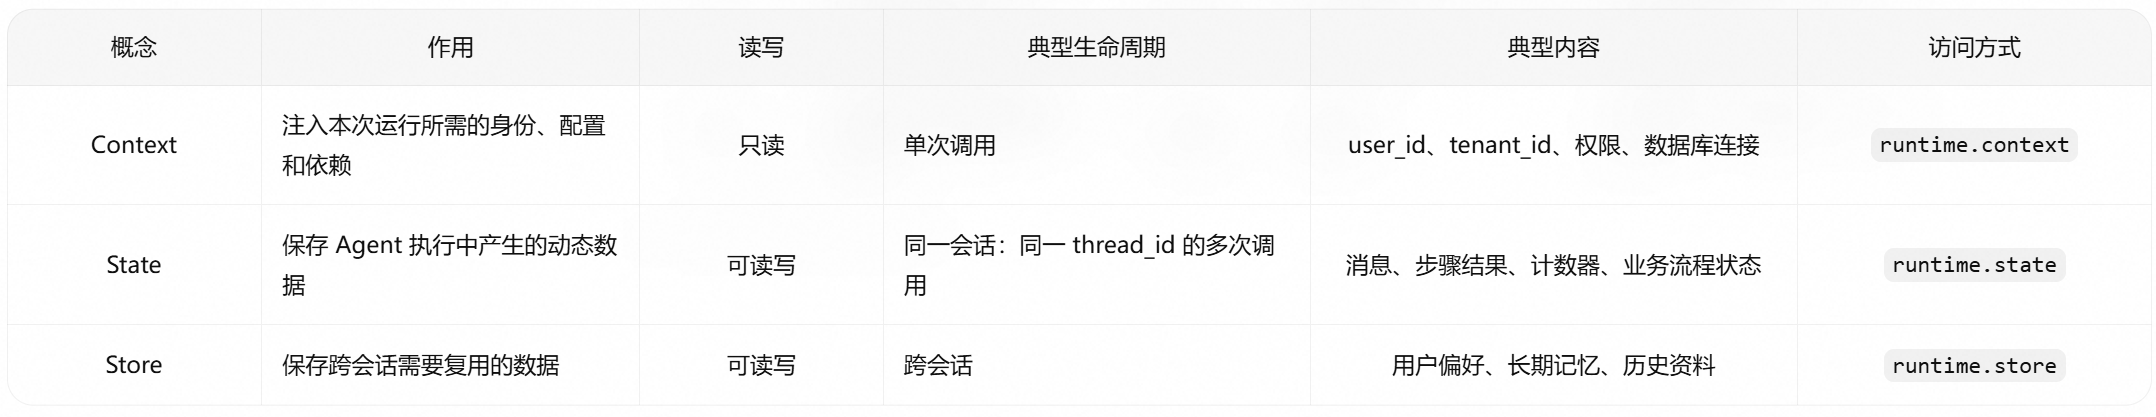


判断数据放在哪里，可以连续问两个问题：
1. 这份数据在执行过程中会不会变化？不变化，优先考虑 Context。
2. 如果会变化，下一次会话还要不要使用？只在当前会话使用放 State，跨会话复用放 Store。


更多Runtime信息可以查看官方文档：[Runtime - Docs by LangChain](https://docs.langchain.com/oss/python/langchain/runtime)
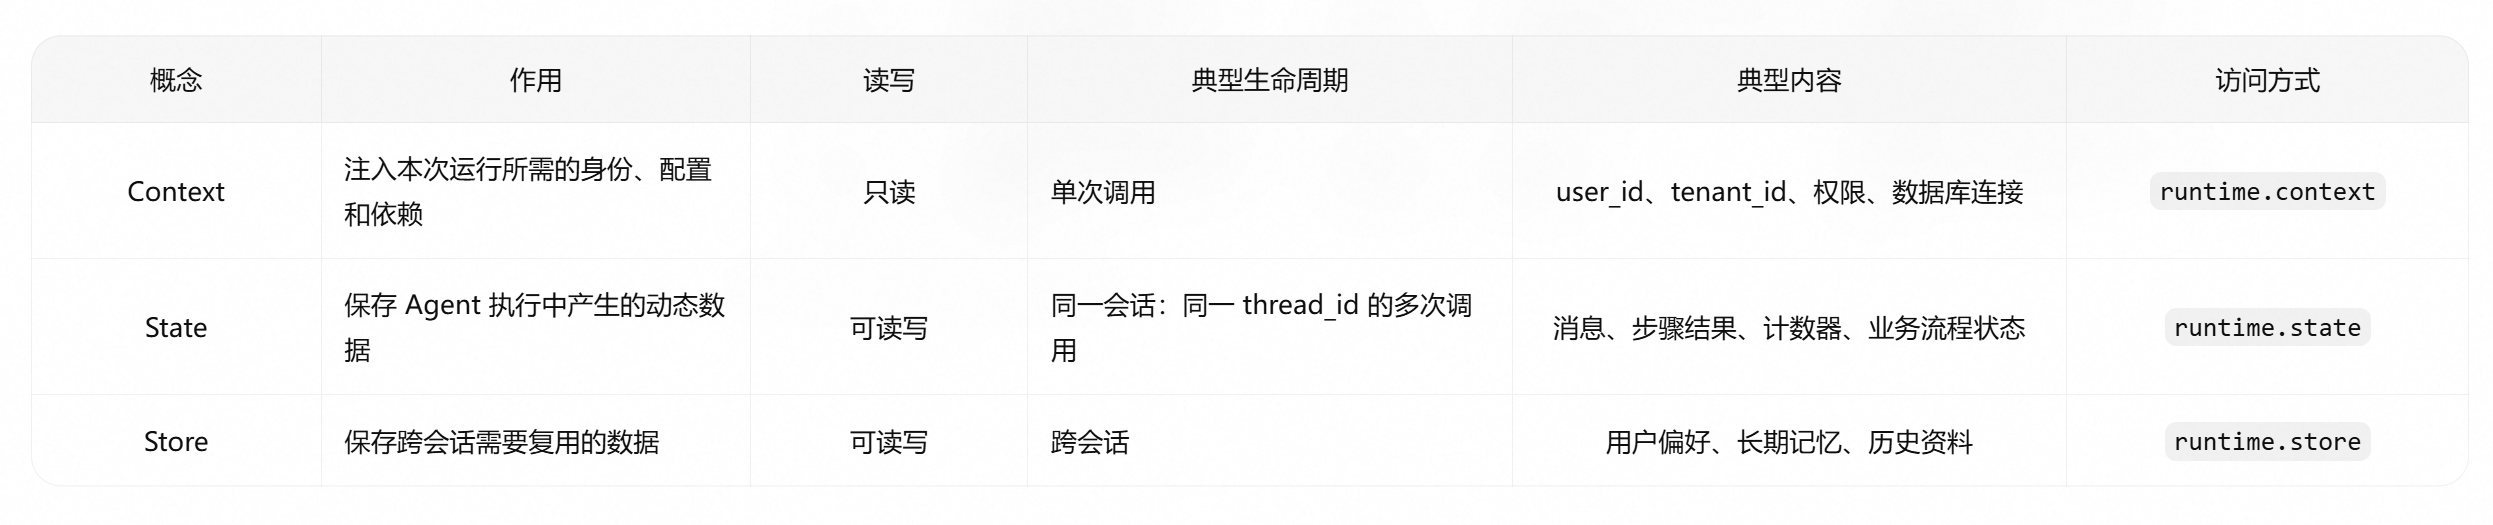
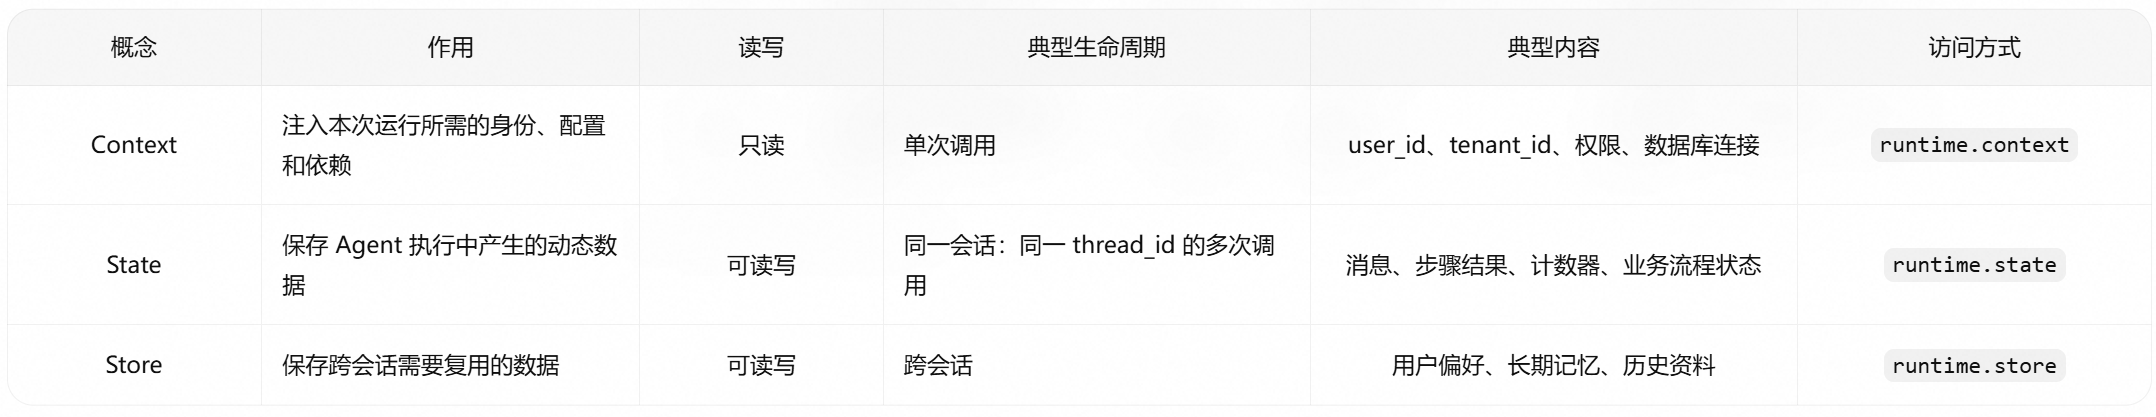

```
LangGraph 提供了一个 `Runtime` 对象，里面包含了下面这些信息：
- Context（上下文）：主要是一些静态信息，比如用户 ID、数据库连接，或者是调用 Agent 时需要的其他依赖项。
- Store（存储）：一个 BaseStore 实例，专门用来做 long-term memory 的。
- Stream writer（流写入器）：当你使用 "custom" 流模式时，就用这个对象来流式输出信息。
- Execution info（执行信息）：当前这次执行的身份标识和重试信息，包括线程 ID（thread ID）、运行 ID（run ID）以及尝试次数（attempt number）。
- Server info（服务器信息）：如果是在 LangGraph Server 上运行，这里会包含一些服务器特有的元数据，比如助手 ID（assistant ID）、图 ID（graph ID）以及经过认证的用户信息。
```

### 1. Context

Runtime context（运行时上下文）其实是为你的节点（Node）、工具（Tools）和中间件（Middleware）提供了依赖注入的功能
- 调用时注入
- 节点、工具和中间件可以通过 `runtime.context` 按需读取
- 生命周期仅限本次运行
- 作用是把隐私数据与Agent解耦

#### 需求：一个多租户的在线教育Agent，具备一个查询用户资料的工具，可以查询当前登录用户的资料
- 模型：决定何时调用工具，但不知道用户身份；
- 调用者：注入`tenant_id` 和 `user_id` 到 `Runtime Context`
- 工具：获取 `Runtime Context`，拿到 `tenant_id` 和 `user_id`，查询用户资料

##### 1. 模拟一个多租户的在线教育项目数据库

In [7]:
# 字典key是租户tenant_id，字典value是租户对应的user信息，也是字典。user字典的key是user_id
USER_DATABASE = {
    "school_a": {
        "u001": {"name": "虎哥", "course": "LangChain 开发指南"},
        "u002": {"name": "小明", "course": "Java开发入门"},
    },
    "school_b": {
        "u001": {"name": "涛哥", "course": "Python 入门"},
        "u002": {"name": "阿伟", "course": "VibeCoding 实战"},
    }
}

##### 2. 定义 `context_schema`

In [8]:
from dataclasses import dataclass
@dataclass(frozen=True) # @dataclass声明类可以省去魔法函数，frozen=True表示数据结构不可修改
class UserContext: # context_schema 定义context数据结构
    """Agent运行时上下文"""
    user_id: str
    tenant_id: str

##### 3. 在 Tool 中使用 Context

In [9]:
from langchain.tools import tool, ToolRuntime

@tool
def get_current_user_profile(runtime: ToolRuntime[UserContext]):
    """查询当前登录用户的资料。"""
    # 获取context
    ctx= runtime.context
    print("ctx: ", ctx)
    # 根据user_id和tenant_id获取用户信息
    profile = USER_DATABASE.get(ctx.tenant_id, {}).get(ctx.user_id)

    # Access thread and run IDs
    execution_info = runtime.execution_info
    print(f"Thread: {execution_info.thread_id}, Run: {execution_info.run_id}")

    # Access server info (only available on LangGraph Server)
    server = runtime.server_info
    if server is not None:
        print(f"Assistant: {server.assistant_id}")
        if server.user is not None:
            print(f"User: {server.user.identity}")

    return (
        f"姓名：{profile['name']}，"
        f"课程：{profile['course']}，"
)

##### 4. 给Agent添加Context

In [10]:
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
model = init_chat_model(
    model="deepseek-v4-flash",
    extra_body={"thinking": {"type": "disabled"}} # 是否开启思考模式 "enabled"、"disabled"
)
agent = create_agent(
    model=model,
    tools=[get_current_user_profile],
    context_schema=UserContext,
    system_prompt="你是课程平台助手。需要用户资料时调用工具。",
)

In [11]:
from langchain.messages import HumanMessage

# 调用时通过Context传递用户信息
response = agent.invoke(
    {"messages": [HumanMessage("Hello, 帮我查询我正在学习的课程")]},
    context=UserContext(user_id="u002", tenant_id="school_a")
)

for message in response['messages']:
    message.pretty_print()

ctx:  UserContext(user_id='u002', tenant_id='school_a')
Thread: None, Run: None
================================ Human Message =================================

Hello, 帮我查询我正在学习的课程
================================== Ai Message ==================================

我需要先查询您的用户资料，才能获取您的课程信息。
Tool Calls:
  get_current_user_profile (call_00_AUzbnDvBdY8qUV0dOElC8557)
 Call ID: call_00_AUzbnDvBdY8qUV0dOElC8557
  Args:
================================= Tool Message =================================
Name: get_current_user_profile

姓名：小明，课程：Java开发入门，
================================== Ai Message ==================================

您好，小明！根据您的用户资料，您正在学习的课程是：

**Java开发入门**

祝您学习顺利！如需了解课程的更多详情（比如章节内容、学习进度等），请告诉我。


### 2. State（短期记忆）

`AgentState` 中只有 `messages` 信息，保存会话历史。但是我们可以继承 `AgentState`，拓展自定义字段，保存其他信息

#### 需求：自定义State，记录调用模型的次数。定义工具，每次调用模型后次数就累加

##### 1. 自定义 state，继承 `AgentState`

In [29]:
# CustomState继承了AgentState以后，不仅可以记录会话的历史消息 `messages`，也能记录Agent运行的任务状态信息了
from langchain.agents import AgentState
# 定义 state_schema 数据结构
class CustomState(AgentState):
    """Agent的任务状态"""
    model_call_count: int  # 模型调用次数

注意事项
- State结构：本质是一个字典，但是结构不能改变（TypedDict），不能动态添加
- 操作方式：必须以字典方式操作 State

##### 2. 在工具中访问state

In [30]:
from langchain.tools import tool, ToolRuntime
from langgraph.types import Command # 指令
from langchain.messages import ToolMessage

@tool
def update_model_call_count(runtime: ToolRuntime):
    """A tool that count model call """

    # 获取state中的model_call_count值，这里要把state当做Dict来操作
    count = runtime.state.get("model_call_count", 0)
    print("model_call_count:", count)

    # 更新State中的数据
    update= {
        "model_call_count": count + 1, # 更新count值
        "messages": [ # 工具执行结束必须返回一条ToolMessage
            ToolMessage(
                content="Successfully updated agent state",
                tool_call_id=runtime.tool_call_id
            )
        ]
    }

    return Command(update=update)

其中的 update 值是一个字典，字典结构就是自定义State的结构，其中包含要更新的字段值：
- `model_call_count`：调用计数
- `messages`：消息列表。这里必须返回一条ToolMessage，作为工具调用的结果。

##### 3. 给 Agent 添加 State

In [31]:
from langchain.agents import create_agent
from langgraph.checkpoint.memory import InMemorySaver

agent = create_agent(
    "deepseek-flash",
    tools=[update_model_call_count],
    state_schema=CustomState,  # 告诉Agent使用自定义的state
    checkpointer=InMemorySaver(),
    system_prompt="你是AI助手，你需要调用工具记录模型调用次数"
)

In [32]:
config = {"configurable": {"thread_id": "1"}}
response = agent.invoke(
    {"messages": [HumanMessage(content="Hi,我是虎哥")]},
    config
)

for message in response['messages']:
    message.pretty_print()

model_call_count: 0
================================ Human Message =================================

Hi,我是虎哥
================================== Ai Message ==================================
Tool Calls:
  update_model_call_count (call_00_3OsLihkwh1cIMSy0B6sV9109)
 Call ID: call_00_3OsLihkwh1cIMSy0B6sV9109
  Args:
================================= Tool Message =================================
Name: update_model_call_count

Successfully updated agent state
================================== Ai Message ==================================

你好，虎哥！很高兴见到你 😄 有什么我可以帮你的吗？


In [33]:
response = agent.invoke(
    {"messages": [HumanMessage(content="还记得我是谁吗")]},
    config
)

for message in response['messages']:
    message.pretty_print()

model_call_count: 1
================================ Human Message =================================

Hi,我是虎哥
================================== Ai Message ==================================
Tool Calls:
  update_model_call_count (call_00_3OsLihkwh1cIMSy0B6sV9109)
 Call ID: call_00_3OsLihkwh1cIMSy0B6sV9109
  Args:
================================= Tool Message =================================
Name: update_model_call_count

Successfully updated agent state
================================== Ai Message ==================================

你好，虎哥！很高兴见到你 😄 有什么我可以帮你的吗？
================================ Human Message =================================

还记得我是谁吗
================================== Ai Message ==================================
Tool Calls:
  update_model_call_count (call_00_ISg11QdyJrBUnv7zqBiq0333)
 Call ID: call_00_ISg11QdyJrBUnv7zqBiq0333
  Args:
================================= Tool Message =================================
Name: update_model_call_count

Successfully updated age

##### 4. 查看state信息

In [34]:
agent.get_state(config)

StateSnapshot(values={'messages': [HumanMessage(content='Hi,我是虎哥', additional_kwargs={}, response_metadata={}, id='c0d7ba96-778d-46e5-a08d-20c779551bfd'), AIMessage(content='', additional_kwargs={'refusal': None, 'reasoning_content': 'We need respond to user. Also must call tool record model call count. User says "Hi, I\'m Hu Ge". Need perhaps friendly greeting. Need call tool. Must call function update_model_call_count. Then final. The tool has no params. Let\'s call.'}, response_metadata={'token_usage': {'completion_tokens': 79, 'prompt_tokens': 292, 'total_tokens': 371, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 55, 'rejected_prediction_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 128}, 'prompt_cache_hit_tokens': 128, 'prompt_cache_miss_tokens': 164}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6', 'id': '8c4cccb

### 3. Store（长期记忆）

保存跨会话需要复用的长期数据，例如用 Store 保存用户偏好

#### 需求：通过 Store 保存用户学习偏好，实现跨会话后 Agent 依然记得用户学习偏好和习惯

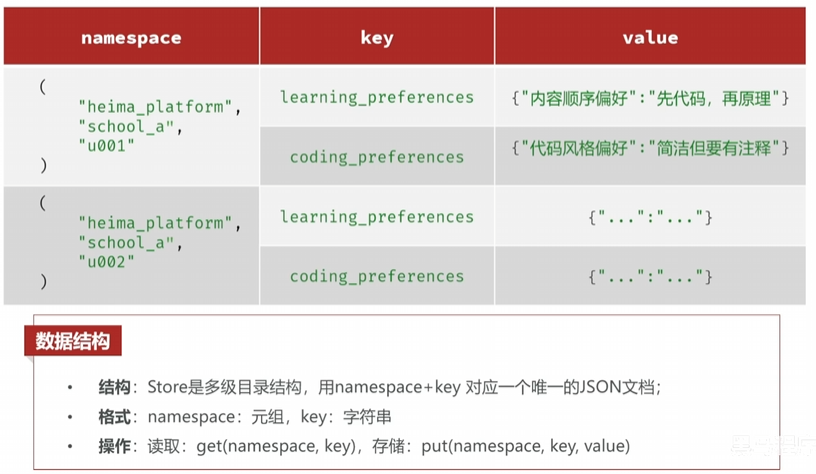
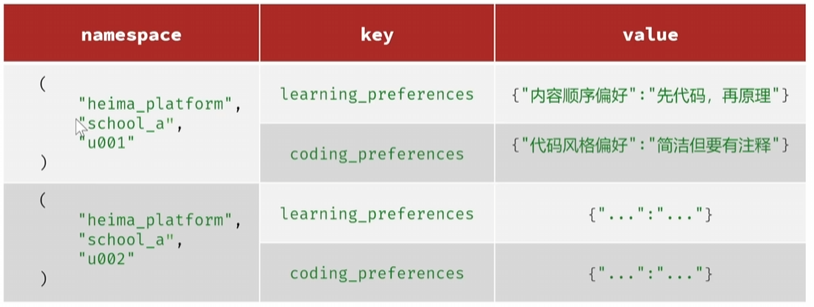
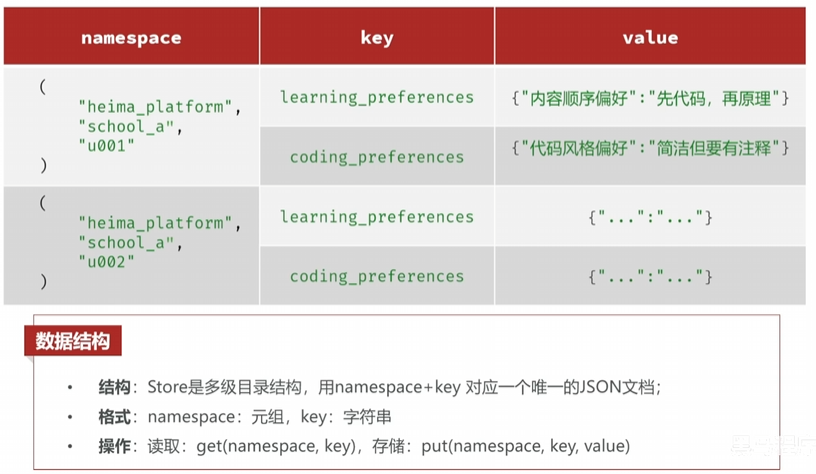
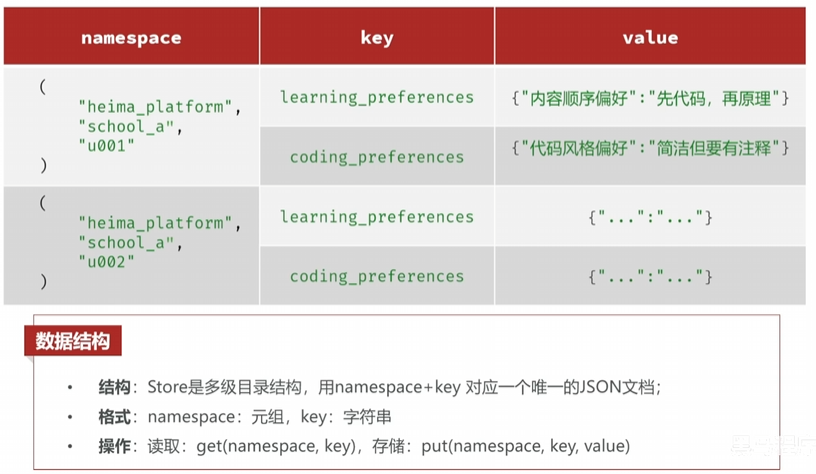

##### 1. 定义 namespace + key

In [6]:
namespace = (
    "heima_platform",  # 黑马程序员平台
    "school_a",        # 租户id，例如某个校区
    "u002"             # 用户id，也就是学员
)

key = "learning_preferences" # key是普通字符串，这里表示学习偏好

##### 2. 在 Tool 中访问 store， 存储学习偏好


In [12]:
from langchain.tools import ToolRuntime, tool

# 定义方法，根据Context中的tenant_id和user_id拼接得到namespace
def preference_namespace(ctx: UserContext) -> tuple[str, ...]:
    return (
        "heima_platform",
        ctx.tenant_id,
        ctx.user_id
    )
# 定义固定的key
key = "learning_preferences"

@tool
def save_learning_preference(
    preference_name: str,
    preference_value: str,
    runtime: ToolRuntime[UserContext],
) -> str:
    """保存当前用户的长期学习偏好。"""

    # 通过上下文中的tenant_id和user_id来构建namespace
    namespace = preference_namespace(runtime.context)

    # 通过namespace和key来读取用户偏好, 返回结果item.value是dict格式
    item = runtime.store.get(namespace, key)
    preferences = dict(item.value) if item else {} # 如果 item 存在，就提取它的 value 属性并转换成字典；如果 item 是 None，就返回一个空字典

    # 记录本次要保存的用户偏好
    preferences[preference_name] = preference_value

    # 保存到Store中
    runtime.store.put(namespace, key, preferences)

    return f"已保存偏好：{preference_name}={preference_value}"


@tool
def get_learning_preferences(
    runtime: ToolRuntime[UserContext],
) -> str:
    """读取当前用户的长期学习偏好。"""

    namespace = preference_namespace(runtime.context)
    item = runtime.store.get(namespace, key)

    if item is None:
        return "当前用户还没有保存学习偏好"

    return f"当前学习偏好：{item.value}"

##### 3. 给 agent 添加 store

In [13]:
from langchain.agents import create_agent             # agent
from langchain.chat_models import init_chat_model     # model
from langgraph.checkpoint.memory import InMemorySaver # state, 存短期记忆, 如会话历史, 靠 thread_id 区分
from langgraph.store.memory import InMemoryStore      # store, 存长期记忆, 如用户偏好
model = init_chat_model(
    model="deepseek-v4-flash",
    extra_body={"thinking": {"type": "disabled"}} # 是否开启思考模式 "enabled"、"disabled"
)
checkpointer = InMemorySaver()
store = InMemoryStore()
agent = create_agent(
    model=model,
    tools=[get_current_user_profile,
           save_learning_preference,
           get_learning_preferences
           ],
    context_schema=UserContext,
    checkpointer=checkpointer,
    store=store,
    system_prompt=(
        "你是课程平台助手。"
        "涉及用户资料时调用资料工具，"
        "涉及长期学习偏好或给用户讲解代码时调用偏好工具。"
    ),
)

In [21]:
context = UserContext(
    user_id="u001",
    tenant_id="school_a",
)

result = agent.invoke(
    {
        "messages": [{"role": "user", "content": "记住：我喜欢先看代码哈哈，再看原理",}]
    },
    config={"configurable": {"thread_id": "thread-c"}},
    context=context,
)
for message in result["messages"]:
    message.pretty_print()

================================ Human Message =================================

记住：我喜欢先看代码哈哈，再看原理
================================== Ai Message ==================================
Tool Calls:
  save_learning_preference (call_00_AhZnOKxMlIBl5WvugxZj9687)
 Call ID: call_00_AhZnOKxMlIBl5WvugxZj9687
  Args:
    preference_name: 学习顺序偏好
    preference_value: 喜欢先看代码示例，再看原理讲解
================================= Tool Message =================================
Name: save_learning_preference

已保存偏好：学习顺序偏好=喜欢先看代码示例，再看原理讲解
================================== Ai Message ==================================

已经记住啦 ✅

偏好已保存：**你喜欢先看代码示例，再看原理讲解**。

以后讲解代码或知识点时，我会按这个顺序来：先给能跑的代码，再解释背后的原理。想调整随时说～


In [22]:
result = agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "langchain如何实现结构化输出？",
            }
        ]
    },
    config={"configurable": {"thread_id": "thread-c"}},
    context=context,
)

for message in result["messages"]:
    message.pretty_print()

================================ Human Message =================================

记住：我喜欢先看代码哈哈，再看原理
================================== Ai Message ==================================
Tool Calls:
  save_learning_preference (call_00_AhZnOKxMlIBl5WvugxZj9687)
 Call ID: call_00_AhZnOKxMlIBl5WvugxZj9687
  Args:
    preference_name: 学习顺序偏好
    preference_value: 喜欢先看代码示例，再看原理讲解
================================= Tool Message =================================
Name: save_learning_preference

已保存偏好：学习顺序偏好=喜欢先看代码示例，再看原理讲解
================================== Ai Message ==================================

已经记住啦 ✅

偏好已保存：**你喜欢先看代码示例，再看原理讲解**。

以后讲解代码或知识点时，我会按这个顺序来：先给能跑的代码，再解释背后的原理。想调整随时说～
================================ Human Message =================================

langchain如何实现结构化输出？
================================== Ai Message ==================================

按你的习惯，先看代码，再看原理 👇

## 一、先看代码

LangChain 提供了 `with_structured_output()`，一行把模型的输出约束成 Pydantic 对象。

```python
from pydantic import BaseMode

### 4. 总结
1. **Context（运行时上下文）**
      - 通过runtime.context访问
      - 用于传递用户ID、配置参数等
      - 生命周期是一次调用
      - 存储方式：基于内存
2. **State（短期记忆）**
      - 通过runtime.state参数访问
      - 用于保存会话历史消息、对话状态、计数等临时信息
      - 生命周期是当前会话
      - 存储方式：可以是InMemorySaver、也可以是数据库
2. **Store（长期记忆）**
      - 通过runtime.store访问
      - 用于拓展知识、用户偏好等信息
      - 生命周期跨越多个会话
      - 支持InMemoryStore和数据库存储

---
更多资源:
- [LangChain官方文档 - Runtime](https://docs.langchain.com/oss/python/langchain/runtime)
- [LangChain官方文档 - Long-term Memory](https://docs.langchain.com/oss/python/langchain/long-term-memory)
- [LangGraph Store文档](https://security.feishu.cn/link/safety?target=https%3A%2F%2Flangchain-ai.github.io%2Flanggraph%2Fconcepts%2Fstore%2F&scene=ccm&logParams=%7B%22location%22%3A%22ccm_docs%22%7D&lang=zh-CN)